In [1]:
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable

import sys
sys.path.append('../src')

from lib_spike_control import *
from utils import *

plt.style.use('tableau-colorblind10')

cmap = matplotlib.colormaps['PRGn']

In [2]:
# Define grid

grid_max = 6.
n_grid = 6001 

grid = np.linspace(0., grid_max, n_grid, endpoint=True)
target = np.zeros(len(grid))

In [3]:
# Set parameters for two different trajectories

a = 1
eps0 = 1
theta = 1/2.5
leak_1 = 0
leak_2 = 3
x0_1 = 2.6
x0_2 = 2.6

z_1, s_1, x_1, x_cont_1, x_jumps_1, x_c_1, z_cont_1 = generate_1d_traj(a, eps0, theta, leak_1, grid, target, x0_1)
z_2, s_2, x_2, x_cont_2, x_jumps_2, x_c_2, z_cont_2 = generate_1d_traj(a, eps0, theta, leak_2, grid, target, x0_2)

upperbound_1 = upperbound_improved(a, eps0, theta, leak_1, x0_1, grid)
upperbound_2 = upperbound(a, eps0, theta, leak_2, x0_2, grid)

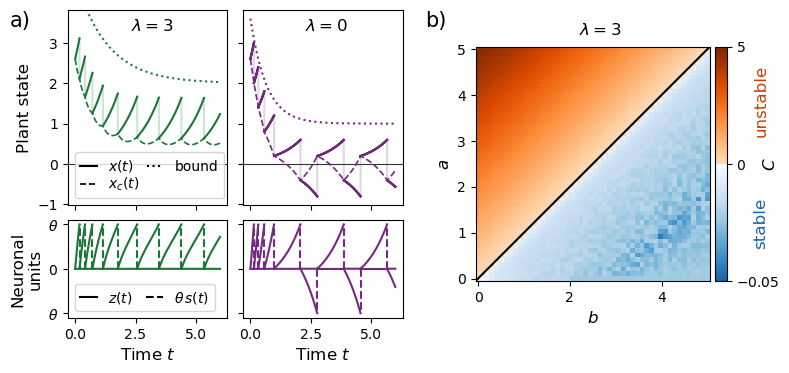

In [4]:
# Variable plot size
resc = 1 # .9

fig = plt.figure(figsize=(8.5*resc, 4*resc))

# Set up the grid for subplots
outer_gs = gridspec.GridSpec(1, 2, width_ratios=[4, 3], figure=fig, wspace=.25)
gs_left = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=outer_gs[0], height_ratios=[2,1], hspace=0.1, wspace=0.1) 

color1 = cmap(0.1)
color2 = cmap(0.9)

ax_x_1 = fig.add_subplot(gs_left[0,1])
ax_s_1 = fig.add_subplot(gs_left[1,1])

ax_x_2 = fig.add_subplot(gs_left[0,0])
ax_s_2 = fig.add_subplot(gs_left[1,0])

# Plot left subplot

# Plot first x trajectory with bounds
ax_x_1.hlines(0, -1, 20, colors='0.2', lw=.8)
ax_x_1.plot(grid, x_cont_1, c=color1)
ax_x_1.plot(grid, x_cont_1, c='0')
ax_x_1.plot(grid, x_cont_1, c=color1)
ax_x_1.plot(grid, x_jumps_1, c=color1, alpha=.2)
ax_x_1.plot(grid, upperbound_1, c=color1, ls='dotted')
ax_x_1.plot(grid, np.insert(x_c_1, 0, np.nan), c=color1, ls='dashed', lw=1.2)

# Plot second x trajectory with bounds
ax_x_2.hlines(0, -1, 20, colors='0.2', lw=.8)
ax_x_2.plot(grid, x_cont_2, c=color2, label='$x(t)$')
ax_x_2.plot(grid, x_jumps_2, c=color2, alpha=.2)
ax_x_2.plot(grid, np.insert(x_c_2, 0, np.nan), c=color2, ls='dashed', lw=1.2, label='$x_c(t)$')
ax_x_2.plot(grid, upperbound_2, c=color2, ls='dotted', label='bound')

# Remove ticks and labels for cleaner look
plt.setp(ax_x_2.get_xticklabels(), visible=False)
plt.setp(ax_x_1.get_xticklabels(), visible=False)
plt.setp(ax_x_1.get_yticklabels(), visible=False)

# Plot spike trains and membrane potentials
ax_s_1.vlines(grid[np.where(s_1[:,0]>0)], 0, theta, ls='dashed', colors=color1)
ax_s_1.vlines(grid[np.where(s_1[:,1]>0)], 0, -theta, ls='dashed', colors=color1)
plt.setp(ax_s_1.get_yticklabels(), visible=False)

ax_s_1.set_yticks((-theta,0,theta))

ax_s_1.plot(grid, z_cont_1[:,0], c=color1, ls='solid')
ax_s_1.plot(grid, -z_cont_1[:,1], c=color1, ls='solid')

ax_s_2.plot(grid, z_cont_2[:,0], c=color2, ls='solid', label='$z(t)$')
ax_s_2.plot(grid, -z_cont_2[:,1], c=color2, ls='solid')

ax_s_2.vlines(grid[np.where(s_2[:,0]>0)], 0, theta, ls='dashed', colors=color2, label='$\\theta \\, s(t)$')
ax_s_2.vlines(grid[np.where(s_2[:,1]>0)], 0, -theta, ls='dashed', colors=color2)

ax_s_2.set_yticks((-theta,0,theta))
ax_s_2.set_yticklabels(('$\\theta$', '$0$', '$\\theta$'))

hl = 1.2

# Define legends
leg1 = ax_x_2.legend(loc=3, framealpha=.8, handlelength=hl, ncol=2, columnspacing=.5, labelspacing=0.1)
leg2 = ax_s_2.legend(loc=3, framealpha=.8, handlelength=hl, ncol=2, columnspacing=1, labelspacing=0.1)

for handle in leg2.legend_handles:
    if hasattr(handle, "set_color"):
        handle.set_color("black")
for handle in leg1.legend_handles:
    if hasattr(handle, "set_color"):
        handle.set_color("black")

ax_x_2.set_ylabel('Plant state', size=12)
ax_s_2.set_ylabel('Neuronal\nunits', size=12)
ax_s_1.set_xlabel('Time $t$', size=12, labelpad=4)
ax_s_2.set_xlabel('Time $t$', size=12, labelpad=4)

ax_x_2.set_ylim(ax_x_1.get_ylim())
ax_s_2.set_ylim(ax_s_1.get_ylim())

ax_x_1.set_xlim(ax_s_1.get_xlim())
ax_x_2.set_xlim(ax_s_2.get_xlim())

# Plot right subplot

# Load precomputed growth matrix
cost_matrix = np.load("../data/growth_matrix_na_50_nb_50_x0_50.5_leak_3.npy")

a_values = np.linspace(0.0, 5, 50)
b_values = np.linspace(0.0, 5, 50)

# Set up mesh plot for cost matrix
X, Y = np.meshgrid(b_values, a_values)

vmin = np.nanmin(cost_matrix)
vmax = np.nanmax(cost_matrix)
vmin, vmax = -0.05, 5

neg_cmap = plt.cm.Blues_r   # darker blues for more negative
pos_cmap = plt.cm.Oranges      # darker reds for more positive

# Build a new colormap with a hard break at 0
# Combine half of each colormap, without blending in the middle
neg_colors = neg_cmap(np.linspace(0.2, 1.0, 128))  # skip very light tones
pos_colors = pos_cmap(np.linspace(0.2, 1.0, 128))

# Concatenate
stacked_colors = np.vstack((neg_colors, pos_colors))
discont_cmap = LinearSegmentedColormap.from_list("discont_bwr", stacked_colors)

norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

ax_right = fig.add_subplot(outer_gs[1])

c = ax_right.pcolormesh(X, Y, cost_matrix, cmap=discont_cmap, shading='auto', norm=norm, rasterized=True)

ax_right.set_xlabel('$b$', size=12)
ax_right.set_ylabel('$a$', size=12)

divider = make_axes_locatable(ax_right)
cax = divider.append_axes("right", size="5%", pad=0.05)
   
cbar = plt.colorbar(c, cax=cax)

cbar.set_label(r'$C$', fontsize=12, labelpad=-13)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks((vmin,0,vmax))
cbar.set_ticklabels(('$-0.05$', '$0$', '$5$'))

ax_right.axis("scaled")

ax_right.plot((-1,6),(-1,6), c='0')

# Additional text annotations
ax_x_2.text(-2.7,3.4, r'a)', fontsize=15)
ax_x_2.text(2.3,3.3, f'$\\lambda = {leak_2}$', fontsize=12)
ax_x_2.text(14.5,3.4, r'b)', fontsize=15)
ax_x_2.text(9.5,3.3, f'$\\lambda = {leak_1}$', fontsize=12)
ax_right.text(2.2,5.3, f'$\\lambda = {leak_2}$', fontsize=12)
ax_right.text(6,.72, 'stable', fontsize=12, color=neg_cmap(.2), rotation='vertical')
ax_right.text(6,3.15, 'unstable', fontsize=12, color=pos_cmap(.8), rotation='vertical')

plt.savefig('../plots/figure2.svg', dpi=300, bbox_inches='tight')